# Effective dimensions results plotting
*Collects analysis data and calculates quantum model's effective dimension*

**By:** Adrian Panasiewicz and Jacob Cybulski<br>
**Date:** May-November 2026<br>

In [1]:
import copy
import pickle
from pathlib import Path
from types import SimpleNamespace

import matplotlib.pyplot as plt
import numpy as np
from itertools import zip_longest

## Plotting function

In [2]:
# Exponential Moving Target used to smooth the lines 
def smooth(scalars, weight):  # Weight between 0 and 1
    last = scalars[0]  # First value in the plot (first timestep)
    smoothed = list()
    for point in scalars:
        smoothed_val = last * weight + (1 - weight) * point  # Calculate smoothed value
        smoothed.append(smoothed_val)                        # Save it
        last = smoothed_val                                  # Anchor the last smoothed value
        
    return smoothed


def plot_many_series(series, smooth_weight=0, xlabel='Iterations', ylabel='Score', figsize=(12, 6), dpi=300, 
                     title='Series Score vs Iteration', labels=None, xlim=None, ylim=None, pref='', colors=None, 
                     loss_curve=None, loss_color='red', loss_label='Loss', legend_loc='best'):

    if labels is None: labels = [None]*len(series)
    if colors is None:
        colors = ['tab:blue', 'tab:orange' ,'tab:green', 'tab:red', 'tab:purple', 'tab:brown', 'tab:pink', 'tab:gray', 'tab:olive', 'tab:cyan']
    if loss_curve is not None:
        loss_mean, loss_sem = loss_curve

    # plt.rcParams['figure.figsize'] = figsize
    # plt.rcParams['figure.dpi'] = dpi
    
    fig, ax1 = plt.subplots(figsize=figsize, dpi=dpi)

    curve_lines = []
    for c in range(len(series)):
        transposed = list(zip_longest(*series[c], fillvalue=np.nan))
        min_curve = smooth([np.nanmin(col) for col in transposed], smooth_weight)
        max_curve = smooth([np.nanmax(col) for col in transposed], smooth_weight)
        mean_curve = smooth([np.nanmean(col) for col in transposed], smooth_weight)        
        if labels[c] is None:
            line = plt.plot(range(1, len(mean_curve)+1), mean_curve, color = colors[c], label=f'Series ({c})')[0]
        else:
            line = plt.plot(range(1, len(mean_curve)+1), mean_curve, color = colors[c], label=labels[c])[0]
        curve_lines.append(line)
        ax1.fill_between(range(1, len(mean_curve)+1), max_curve, min_curve, color = colors[c], alpha = 0.2)
        
    ax1.set_xlabel(xlabel)
    ax1.set_ylabel(ylabel)
    if xlim is not None: ax1.set_xlim(xlim)
    if ylim is not None: ax1.set_ylim(ylim)

    if loss_curve is not None:
        ax2 = ax1.twinx()
        ax2.set_ylabel(loss_label)
        
        ebars = ax2.errorbar(
            range(1, len(loss_mean)+1), 
            loss_mean, 
            yerr=loss_sem,      # Specify the vertical error bounds
            fmt='--',           # Format string: '-' connects lines, 'o' makes circular markers
            color=loss_color,   # Color of the line and markers
            ecolor=loss_color,  # Color of the error bars
            elinewidth=1,       # Width of the error bar lines
            capsize=3,          # Adds horizontal caps to the ends of the error bars
            capthick=1,       # Thickness of the horizontal caps
            label=loss_label
        )   
        curve_lines.append(ebars)
        
    all_labels = [l.get_label() for l in curve_lines]
    ax1.legend(curve_lines, all_labels, loc=legend_loc)
    fig.tight_layout()
    plt.title(title)
    plt.show()


## Helper functions

In [3]:
def parameter_count_factory(depth):
    return SimpleNamespace(parameter_count=12 * int(depth))


def mean_and_sem(values):
    values = np.stack(values, axis=0).astype(float)
    mean = values.mean(axis=0)
    sem = values.std(axis=0, ddof=1) / np.sqrt(values.shape[0])
    return mean, sem


def aggregate_results(runs, key):
    results = [run[key] for run in runs]
    depths = np.asarray(results[0].depths)

    if any(
        not np.array_equal(np.asarray(result.depths), depths)
        for result in results
    ):
        raise ValueError(f"Depths differ between runs for {key}.")

    mean, sem = mean_and_sem(
        [np.asarray(result.means, dtype=float) for result in results]
    )

    aggregated = copy.copy(results[0])
    object.__setattr__(aggregated, "means", mean)
    object.__setattr__(aggregated, "standard_errors", sem)

    return aggregated


def aggregate_uneven_results(runs, key):
    results = [run[key] for run in runs]
    means = [float(np.mean(r.means)) for r in results]
    sems = [float(np.std(r.means, ddof=1) / np.sqrt(len(r.depths))) for r in results]

    aggregated = copy.copy(results[0])
    object.__setattr__(aggregated, "means", means)
    object.__setattr__(aggregated, "standard_errors", sems)

    return aggregated


def aggregate_uneven_eds(runs, key):
    results = [run[key] for run in runs]
    runs_no = len(results)
    means_list = [r.means for r in results]
    depths = [len(l) for l in means_list]
    return means_list, depths


def aggregate_uneven_losses(runs, key):
    results = [run[key] for run in runs]
    losses = [[r[depth] for depth in sorted(r)] for r in results]
    depths = [len(l) for l in losses]
    high_depth = max(depths)
    depth_vals = []
    for d in range(high_depth):
        vals = []
        for l in losses:
            if len(l) > d:
                vals.append(l[d])
        depth_vals.append(vals)
    loss_mean = [float(np.mean(dvals)) for dvals in depth_vals]
    loss_sem = [float(np.std(dvals) / np.sqrt(len(dvals))) for dvals in depth_vals]

    return loss_mean, loss_sem, depths

## Data collection

In [4]:
results_dir = Path("results")
seeds = range(2026, 2033)
runs = []

for seed in seeds:
    ext_path = results_dir / f"depth_11_15_extension_{seed}.pkl"
    path = results_dir / f"trained_prefix_led_ged_results_{seed}.pkl"
    if ext_path.is_file():
        print(f'Collecting *extended seed: {seed}')
    else:
        print(f'Collecting  standard seed: {seed}')
    with path.open("rb") as f:
        runs.append(pickle.load(f))

led_means, led_max_depths = aggregate_uneven_eds(runs, "led_result")
ged_means, ged_max_depths = aggregate_uneven_eds(runs, "ged_result")
loss_mean, loss_sem, loss_max_depths = aggregate_uneven_losses(runs, "test_losses")

### Sample data

In [5]:
(led_means[3:5], led_max_depths)

([[0.4240711499710022,
   0.5624929019921453,
   0.5027738328255917,
   0.5837915229149739,
   0.5433583324081437,
   0.5060657733305952,
   0.6954028760681181,
   0.6830978302599038,
   0.6674142767117182,
   0.6549410626120562],
  [0.45500337322429923,
   0.4550586866535825,
   0.518475603974924,
   0.7055392122335077,
   0.5505437583418831,
   0.7188745477625597,
   0.7025586802201296,
   0.6835444846921518,
   0.6749516042278798,
   0.3828802618493589,
   0.6372069653311168,
   0.3478652779201519,
   0.6064032228822874,
   0.23839867789907787,
   0.5759913164281396]],
 [10, 10, 10, 10, 15, 15, 10])

In [6]:
(loss_mean, loss_sem, loss_max_depths)

([0.0028296746596338587,
  0.002462908792105939,
  0.0021266681777678885,
  0.0014872348319630222,
  0.0013853943774493336,
  0.0009210786890226757,
  0.0007037313893250685,
  0.000905851772782228,
  0.0006820959204101137,
  0.0006851647035244188,
  0.0007452894094444777,
  0.0009274253531067255,
  0.001183887396776139,
  0.0015701688217492466,
  0.0002565350281848063],
 [5.1364550216302876e-05,
  0.0001556083171240507,
  0.00015818443652072396,
  0.00017277257659656484,
  0.00017263367780235022,
  9.515332394275661e-05,
  0.00012038588599551931,
  0.00020647458939953246,
  0.00013130819305512455,
  0.00010708216530636414,
  0.0001687133036204895,
  2.9483460628914632e-05,
  0.0006273231885183308,
  0.0003626091732878171,
  8.886713796626641e-05],
 [10, 10, 10, 10, 15, 15, 10])

## Plot normalized and unnormalized effective dimension

### Normalized ED plot

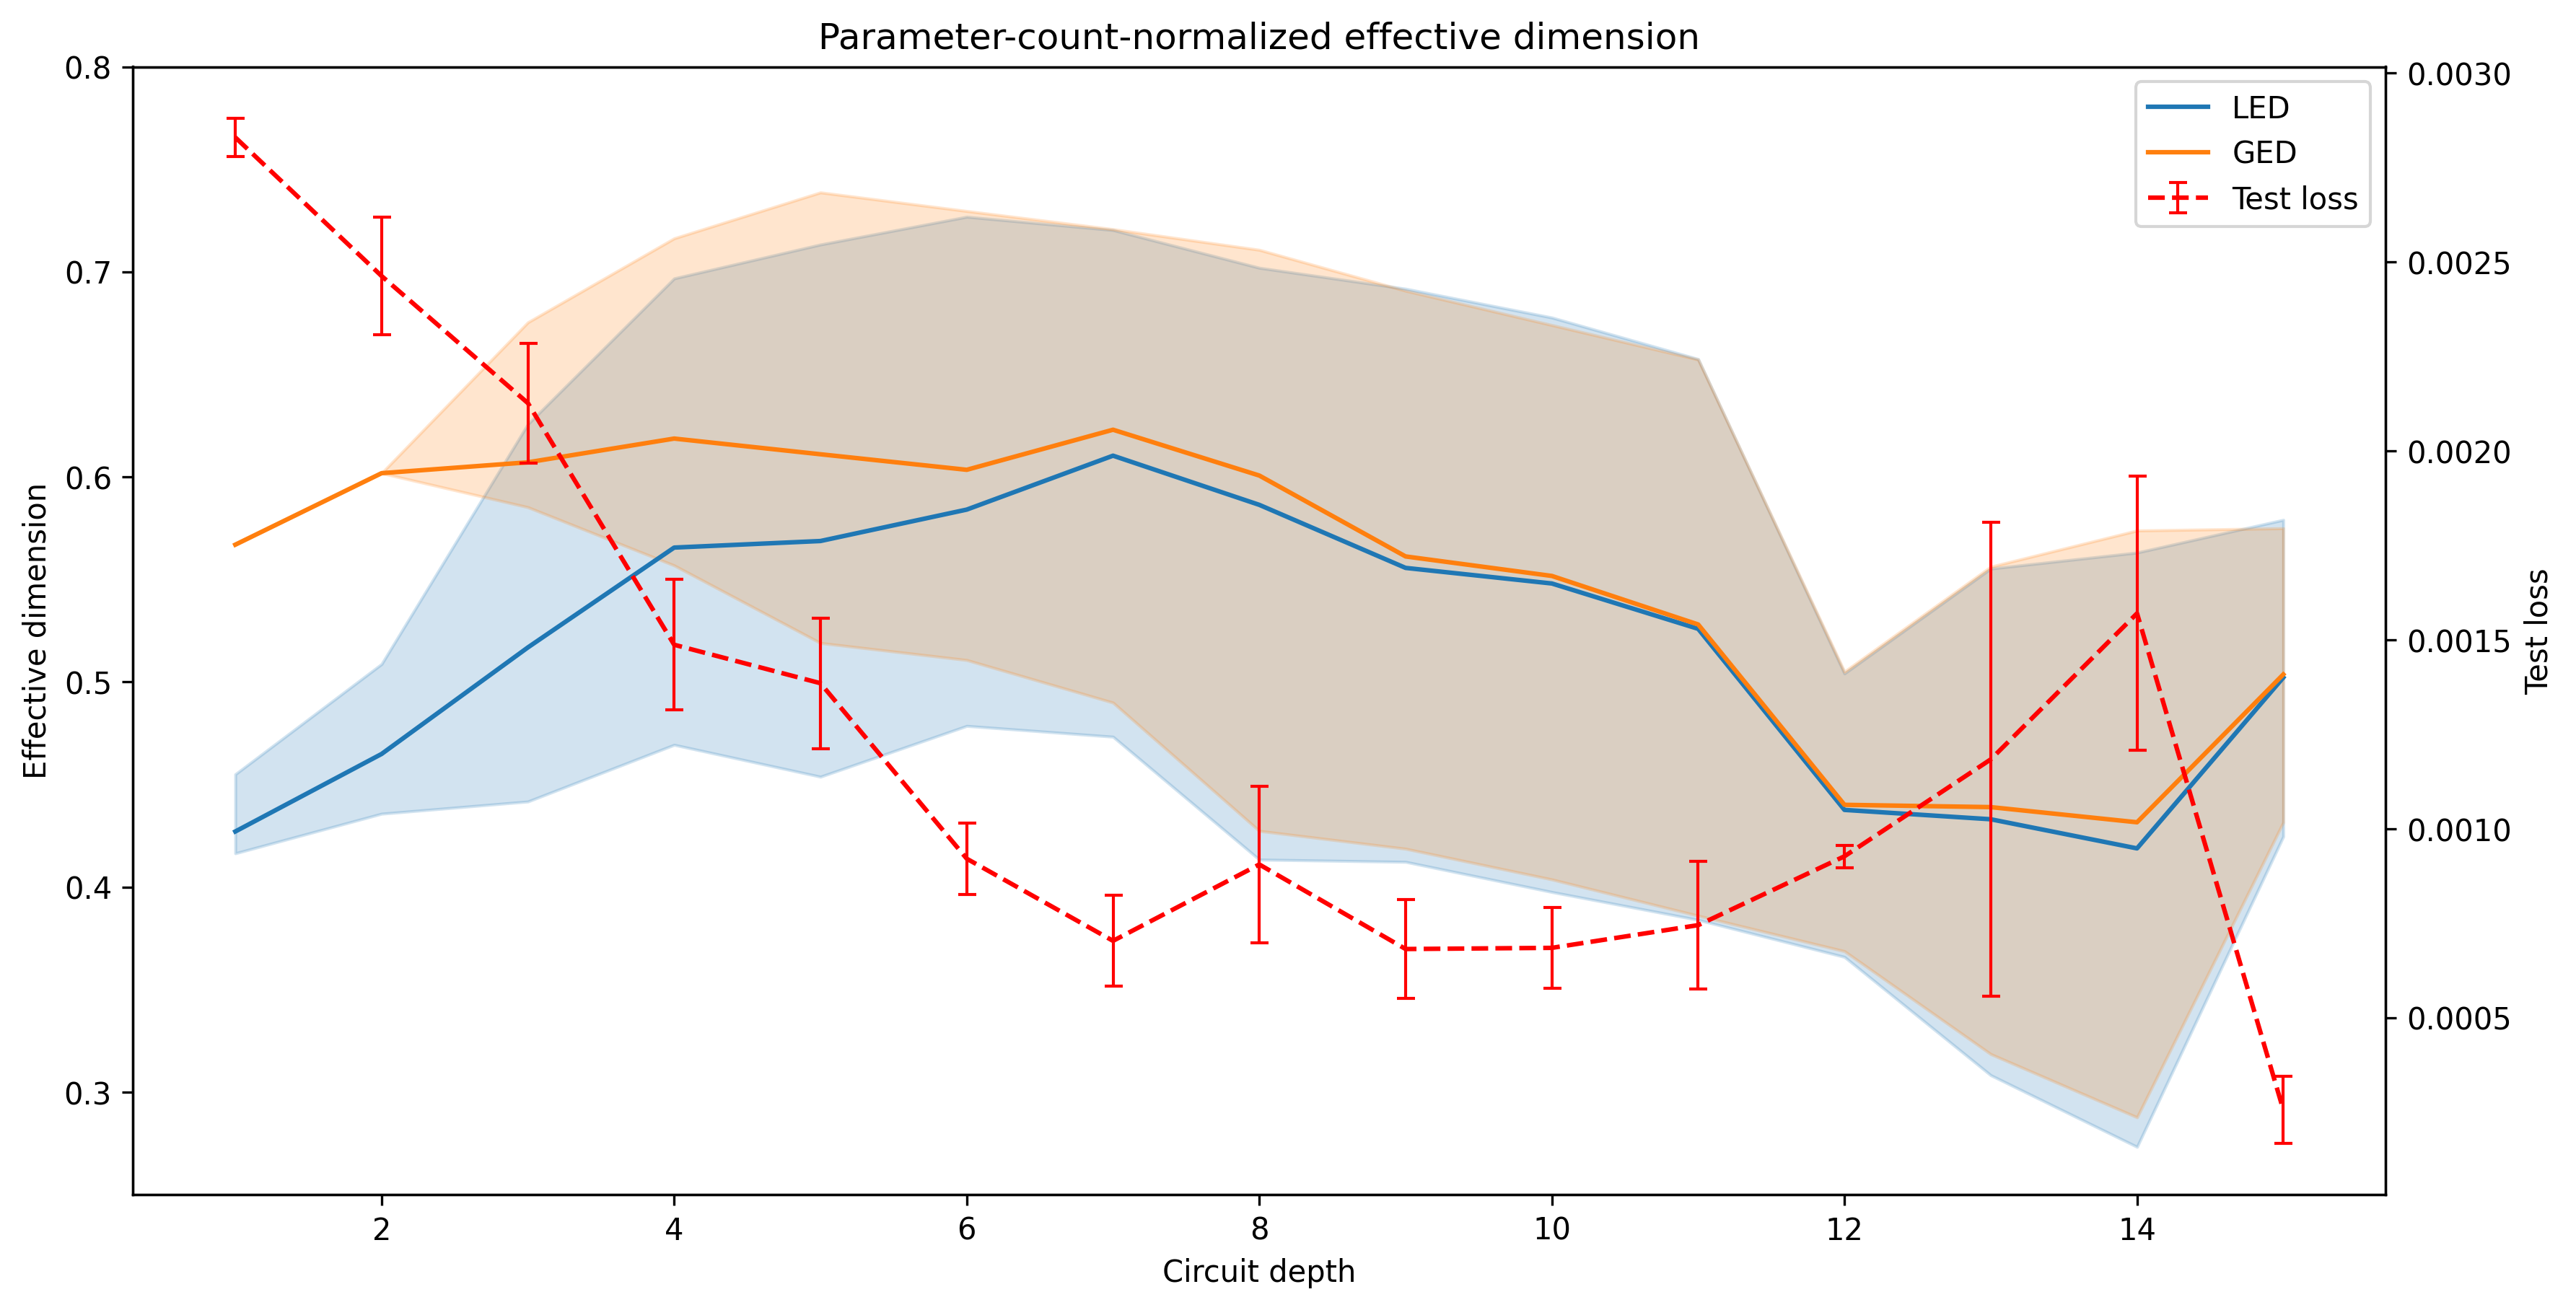

In [7]:
plot_many_series([led_means, ged_means], loss_curve=(loss_mean, loss_sem), 
    xlabel='Circuit depth', ylabel='Effective dimension', 
    title='Parameter-count-normalized effective dimension', labels=['LED', 'GED'], loss_label='Test loss',
    xlim=None, ylim=(0.25, 0.8), smooth_weight=0.5, figsize=(12, 6), dpi=300)

### Unnormalized ED plot

In [8]:
### Unnormalize data
pcf = parameter_count_factory
led_unn_means = [[run[d] * pcf(d).parameter_count for d in range(len(run))] for run in led_means]
ged_unn_means = [[run[d] * pcf(d).parameter_count for d in range(len(run))] for run in ged_means]

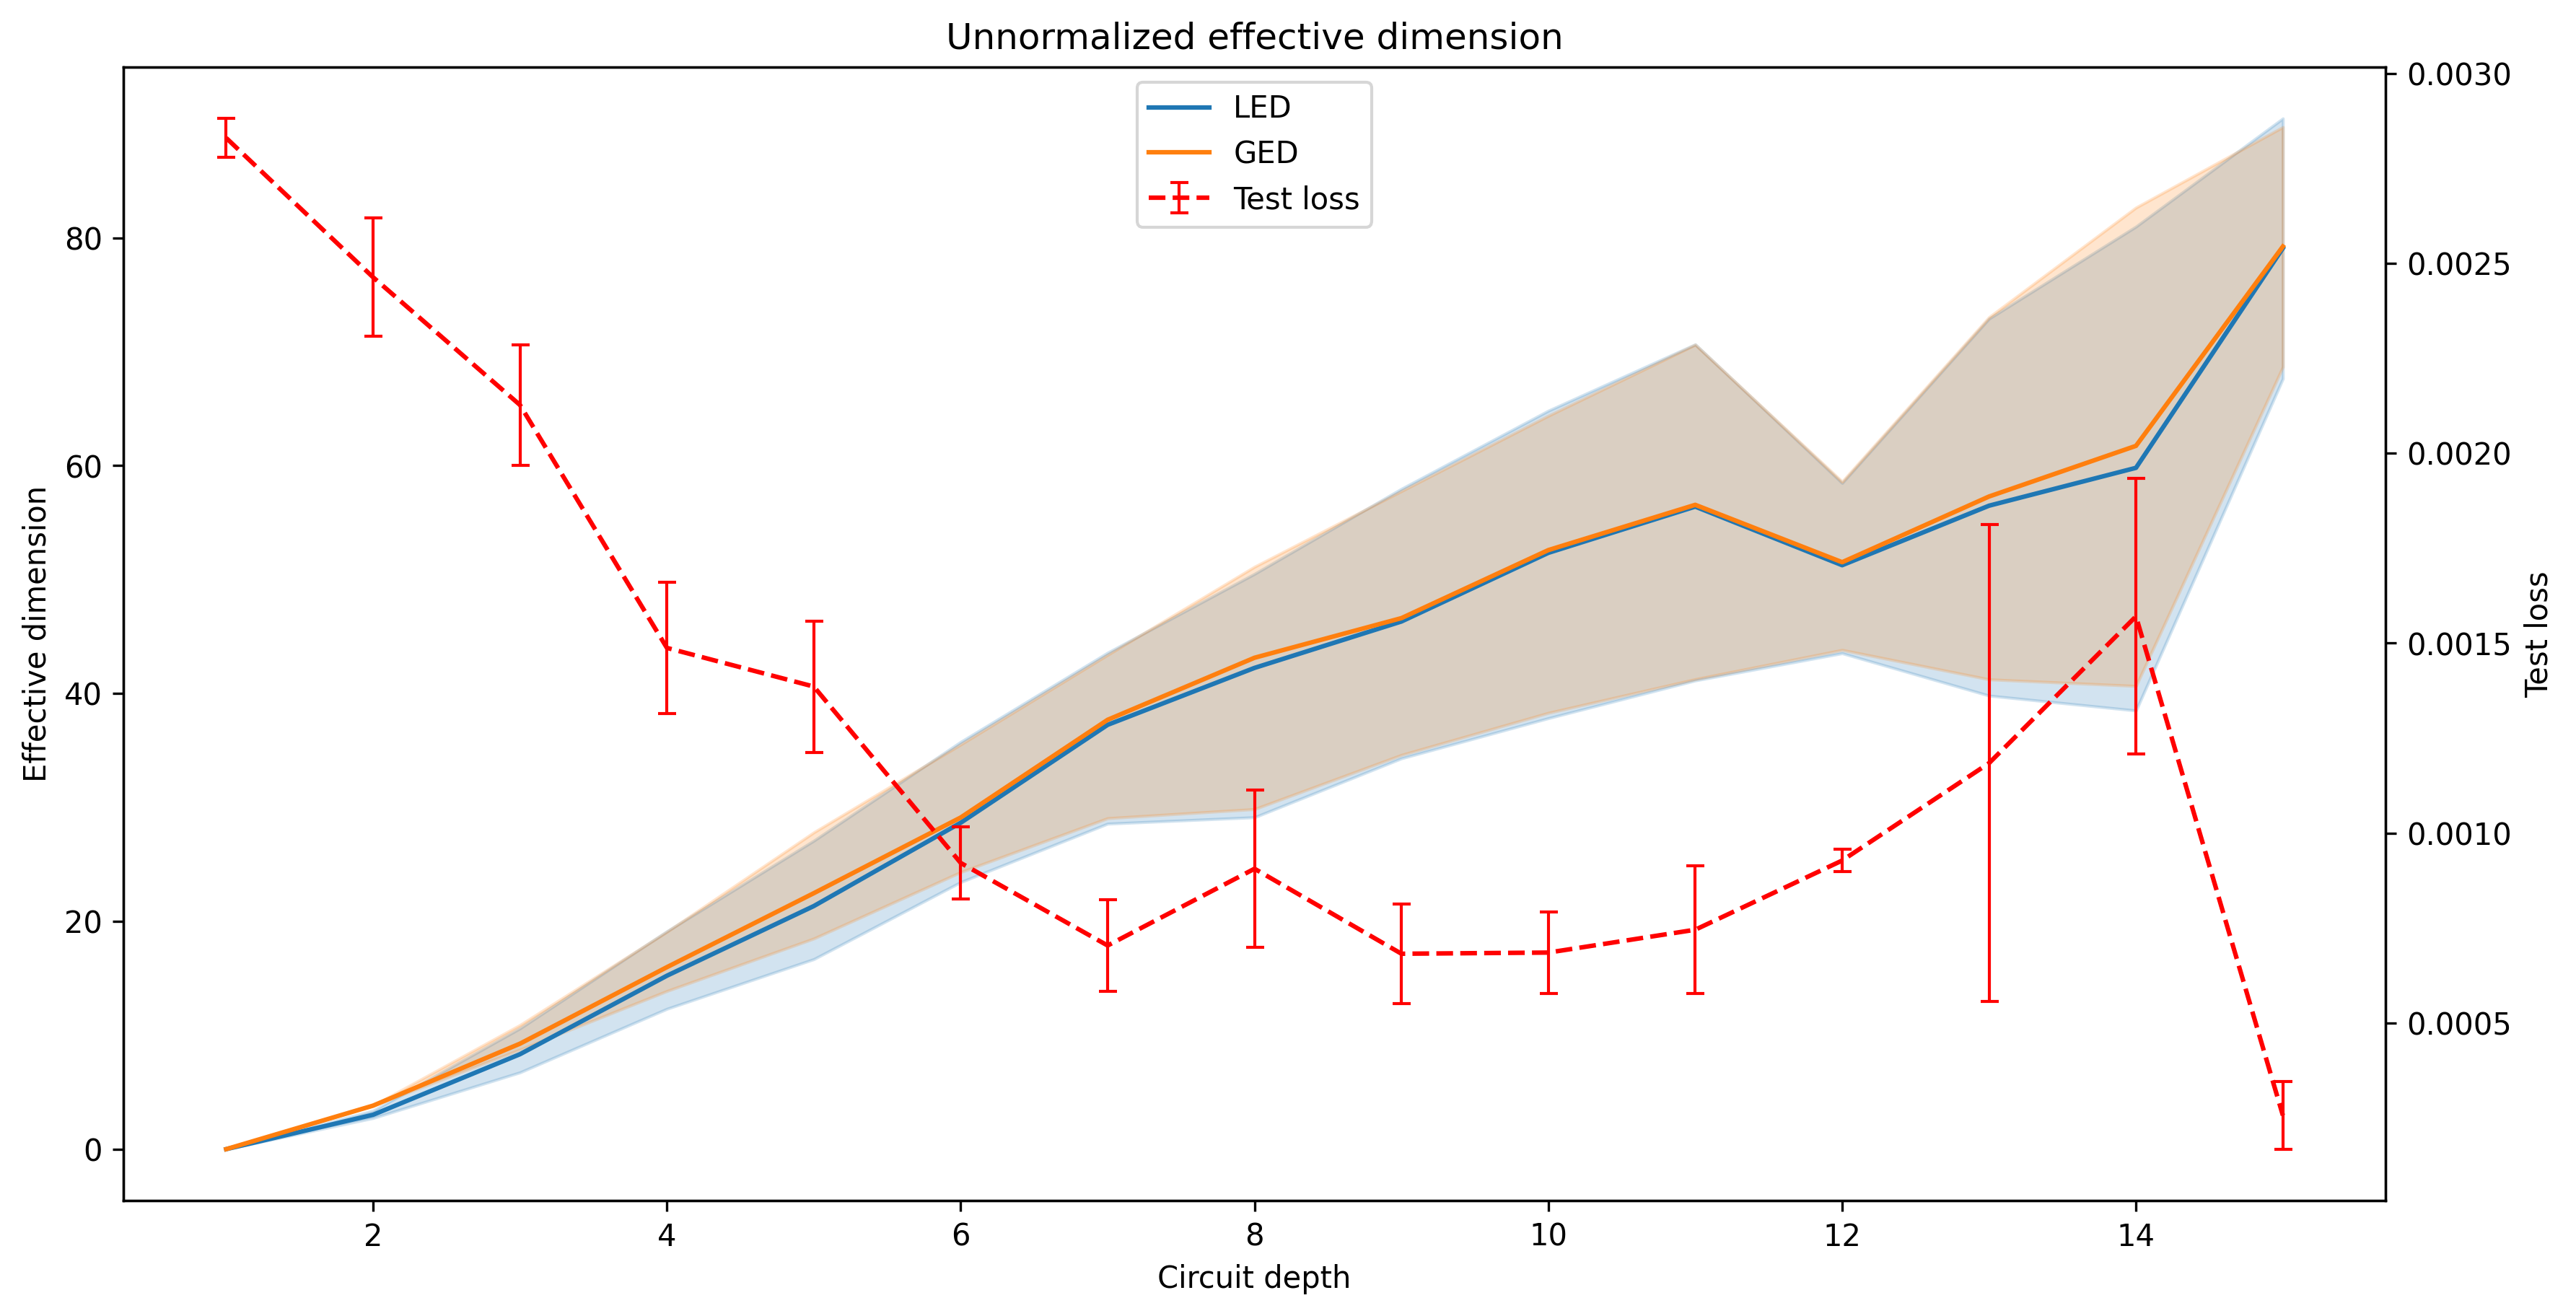

In [9]:
plot_many_series([led_unn_means, ged_unn_means], loss_curve=(loss_mean, loss_sem), 
    xlabel='Circuit depth', ylabel='Effective dimension', legend_loc='upper center',
    title='Unnormalized effective dimension', labels=['LED', 'GED'], loss_label='Test loss',
    xlim=None, ylim=None, smooth_weight=0.5, figsize=(12, 6), dpi=300)

## Systems in use (Linux)

In [10]:
!pip list | grep -e pennylane -e torch

pennylane                 0.45.0
pennylane_catalyst        0.15.0
pennylane_lightning       0.45.0
pennylane_lightning_gpu   0.45.0
torch                     2.11.0+cpu
torchaudio                2.11.0
torcheval                 0.0.7
torchmetrics              1.9.0
torchsummary              1.5.1
torchvision               0.26.0+cpu
